# Structural identifiability (Stigter and Molenaar 2015)

Port of the legacy interactive notebook `legacy/notebooks/structural_identifiability.ipynb` to the new API (`src/identifiability/`). The legacy notebook plotted files written by old stand-alone scripts for two models; here the analysis is **run in the notebook** with the library functions the selection uses (`structural.py`, `output_level.py`), and the saved outputs of the selection (`reduction/structural_spectra/`, `structural_per_iteration.csv`, `fixing_log.csv`, `final/output_level_classes.csv`) are loaded for the rest. Only the free-drain flux model is ported: the fixed-drain "paper v2" variant of the legacy notebook is not part of the v3/v4 pipeline.

**The question.** A direction in log-parameter space is *structurally* null if no data set can determine it, however precise. The test works on the rate laws alone: outputs = the 9 reaction rates $v_r$ at the fitted states of the 22 conditions, relative sensitivity matrix (ROSM)

$$ S_{ij} \;=\; \frac{\theta_j}{v_i}\,\frac{\partial v_i}{\partial \theta_j}\qquad (\text{rows } i = (\text{condition},\text{reaction}),\ \text{columns } j = \text{free parameters}), $$

exact (CasADi Jacobian of the rate laws of `model/kinetics.py`). With the SVD $S = U\Sigma V^\top$, a direction is a **structural zero** if $\sigma_k/\sigma_{\max} < 10^{-10}$ in **all** $q+1$ realizations $\theta_i = \hat\theta\,e^{U(\ln 0.5,\ \ln 1.5)}$ (realization 0 is the anchor itself). The null space is the consensus of the per-realization null spaces; with the projector $P$ onto it, the parameters with $P_{jj} > 0.05$ form the **null groups**, a reduced-row-echelon basis gives the combination, and a sympy computation of the exact symbolic null vectors classifies each group as `exact`, `mixed` or `point-dependent` (null at this anchor only). For instance $K_{s,f6p}^3$ and $K_{s,atp}^3$ of PFK only enter through their product, so the direction $(+1,-1)$ in $(\ln K_{s,f6p}^3, \ln K_{s,atp}^3)$ is a structural null direction (only the product is determined) and one of the two is fixed.

This rate-level test is only a **necessary** condition: free cofactors, drains and unmeasured states of the estimation problem can absorb further rate changes, which is the output-level test (section 4). The selection runs both at the start of every iteration; the equations and the fixing rules are in `parameter_selection.ipynb`.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import glob
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from settings import THETA_BOUNDS, THRESHOLDS, default_params
from model.parameters import ALL_PARAMS
from estimation.anchors import load_point, read_anchor
from identifiability.structural import (RateLaws, condition_states, analyse_free_set, spectra_frame, null_projector,
                                        groups_from_projector, group_basis, basis_strings, symbolic_null_vectors,
                                        exact_vectors_free, match_exact)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)

RED = os.path.join(OUT, "reduction")
STRUCT = os.path.join(OUT, "structural")
RUN_COLORS = {"anchor": "black"}
for i in range(1, THRESHOLDS["structural_q"] + 1):
    RUN_COLORS["r%02d" % i] = plt.cm.tab10((i - 1) % 10)

def read_optional(path, **kw):
    """pd.read_csv, or None with a message if the file is not there (e.g. an output only a newer run writes)."""
    if os.path.exists(path):
        return pd.read_csv(path, **kw)
    print("not found (written by the live cell with HK_RUN=1, or by a newer run?): " + os.path.relpath(path, OUT))
    return None

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : True (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 1. The analysis at the stage-0 anchor (live)

Skipped unless `HK_RUN=1` (a few seconds; it writes only `OUT/structural/`). Steps, all with library functions:

1. `load_point(OUT/stage0)`: the stage-0 anchor (theta, balanced metabolites, cofactors and drains of every condition) as an estimator without a solve;
2. `condition_states`: the fitted operating point of the 22 conditions, `RateLaws`: the CasADi rate functions $v(C,E,\theta)$ and $\partial v/\partial\theta$;
3. `analyse_free_set`: $q=10$ random realizations (`params["structural_q"]`) plus the anchor, SVD of every ROSM, consensus null space, projector $P$. The seed is the one of the first structural check of the selection (`seed_base` + iteration 0), so this reproduces round 0 of iteration 0;
4. the exact symbolic null vectors (`symbolic_null_vectors`) and `groups_from_projector` / `group_basis` / `match_exact`: the null groups, their sparse basis and class.

In [2]:
# Settings of the structural check (defaults from settings/thresholds.csv)
params = default_params("structural")
params["structural_q"] = 10              # random parameter realizations besides the anchor
params["structural_sv_tol"] = 1e-10      # a structural zero: singular value ratio below this in ALL realizations
params["structural_load_min"] = 0.05     # null group member: diagonal of the null-space projector above this
params

{'structural_q': 10,
 'structural_q_out': 5,
 'seed_base': 1000,
 'final_seed_base': 9000,
 'perturb_seed_offset': 5000,
 'structural_sv_tol': 1e-10,
 'structural_guard_rel': 1e-06,
 'structural_load_min': 0.05,
 'tie_rtol': 0.25,
 'realization_lo': 0.5,
 'realization_hi': 1.5,
 'perturb_lo': 0.5,
 'perturb_hi': 2.0,
 'output_realization_lo': 0.5,
 'output_realization_hi': 2.0,
 'output_perturb_lo': 0.5,
 'output_perturb_hi': 2.0,
 'active_rtol': 0.0001,
 'rank_rcond': 1e-10}

In [3]:
anchor_dir = os.path.join(OUT, "stage0")
free_all = list(ALL_PARAMS)
if RUN:
    os.makedirs(STRUCT, exist_ok=True)
    state = read_anchor(anchor_dir)
    est = load_point(state)
    rate_laws = RateLaws()
    states = condition_states(est)
    theta_full = est.full_theta()
    anchor = {p: float(theta_full[p]) for p in ALL_PARAMS}
    # the seed of the first structural check of the selection (iteration 0, round 0)
    seed = params["seed_base"]
    analysis = analyse_free_set(rate_laws, anchor, THETA_BOUNDS, states, free_all, params, seed)
    analysis_pert = analyse_free_set(rate_laws, anchor, THETA_BOUNDS, states, free_all, params, seed, perturbed=True,
                                     state_seed=seed + params["perturb_seed_offset"])
    print("stage-0 anchor objective %.4f, %d free parameters" % (state["obj"], len(free_all)))
    print("null dimension per realization (anchored states):", analysis["counts"], "-> consensus", analysis["N"].shape[1])
    print("null dimension per realization (all states perturbed, check only):", analysis_pert["counts"])

    symbolic = symbolic_null_vectors(print)
    exact = exact_vectors_free(symbolic, free_all)
    exact_projector = exact.T @ exact if exact.shape[0] else None
    groups = groups_from_projector(analysis["P"], free_all, params["structural_load_min"], exact_projector)
    for g in groups:
        g["R"], g["pivots"] = group_basis(analysis["P"], g["idx"])
        g["vectors"] = basis_strings(g["R"], g["members"])
    match_exact(groups, exact, free_all)

    spectra_before = spectra_frame(analysis)
    # the last right singular vector of every run, with the sign of its largest entry made positive
    last_vector = pd.DataFrame({name: Vt[-1] for name, Vt in zip(analysis["names"], analysis["Vts"])}, index=free_all)
    for name in last_vector.columns:
        v = last_vector[name].to_numpy()
        last_vector[name] = np.sign(v[np.argmax(np.abs(v))]) * v
    projector_diagonal = {}
    for name, Vt, ratio in zip(analysis["names"], analysis["Vts"], analysis["ratios"]):
        projector, _n_zero = null_projector(Vt, ratio, params["structural_sv_tol"])
        projector_diagonal[name] = np.diag(projector)
    proj_diag = pd.DataFrame(projector_diagonal, index=free_all)
    rows = []
    for g in groups:
        rows.append({"reaction": g["reaction"], "members": ";".join(g["members"]), "dim": g["dim"], "class": g["cls"],
                     "exact_dim": g["d_exact"], "null_vectors": " | ".join(g["vectors"])})
    groups_table = pd.DataFrame(rows)

    spectra_before.to_csv(os.path.join(STRUCT, "spectra_before.csv"))
    last_vector.to_csv(os.path.join(STRUCT, "last_right_singular_vector_before.csv"))
    proj_diag.to_csv(os.path.join(STRUCT, "null_projector_diag_before.csv"))
    groups_table.to_csv(os.path.join(STRUCT, "null_groups.csv"), index=False)
    print("written to", STRUCT)
else:
    print("RUN is False: the live analysis is skipped; its saved result is read from", STRUCT)

stage-0 anchor objective 11.7455, 37 free parameters
null dimension per realization (anchored states): [9, 8, 9, 9, 9, 8, 9, 9, 9, 9, 9] -> consensus 8
null dimension per realization (all states perturbed, check only): [8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]


symbolic pts: generic nullity 0 (verified True) [0.3s]
symbolic pgi: generic nullity 0 (verified True) [0.1s]


symbolic pfk: generic nullity 2 (verified True) [0.2s]
symbolic fba: generic nullity 1 (verified True) [0.1s]


symbolic tpi: generic nullity 0 (verified True) [0.1s]


symbolic gap: generic nullity 3 (verified True) [0.4s]


symbolic pgk: generic nullity 2 (verified True) [0.2s]
symbolic gpm: generic nullity 0 (verified True) [0.1s]
symbolic eno: generic nullity 0 (verified True) [0.1s]
written to /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model/structural


### Null groups found at the stage-0 anchor

Each row is a parameter group that only appears in a combination; `null_vectors` give the null directions in log-parameters (`+1*A -1*B`: moving $\ln A$ up and $\ln B$ down by the same amount changes nothing, only the product $A\,B$ is determined). `class` is `exact` when the symbolic null space of the rate law has the full numerical dimension.

In [4]:
groups_table = read_optional(os.path.join(STRUCT, "null_groups.csv"))
groups_table

,reaction,members,dim,class,exact_dim,null_vectors
0,pfk,Ks_f6p_3;Ks_atp_3,1,exact,1,+1*Ks_f6p_3 -1*Ks_atp_3
1,pfk,Kp_fbp_3;Kp_adp_3,1,exact,1,+1*Kp_fbp_3 -1*Kp_adp_3
2,fba,Kp_g3p_4;Kp_dhap_4,1,exact,1,+1*Kp_g3p_4 -1*Kp_dhap_4
3,gap,Ks_g3p_6;Ks_pi_6;Ks_nad_6,2,exact,2,+1*Ks_g3p_6 -1*Ks_nad_6 | +1*Ks_pi_6 -1*Ks_nad_6
4,gap,Kp_pgp_6;Kp_nadh_6,1,exact,1,+1*Kp_pgp_6 -1*Kp_nadh_6
5,pgk,Ks_pgp_7;Ks_adp_7,1,exact,1,+1*Ks_pgp_7 -1*Ks_adp_7
6,pgk,Ks_3pg_7;Ks_atp_7,1,exact,1,+1*Ks_3pg_7 -1*Ks_atp_7


## 2. Last right singular vector and null-space projector

The singular vector of the smallest singular value rotates inside a degenerate null space from one realization to the next (top panel), so it cannot be read directly; the diagonal of the null-space projector is rotation invariant (bottom panel): a parameter with a diagonal close to 1 takes part in a null direction. The dashed line is the membership threshold 0.05.

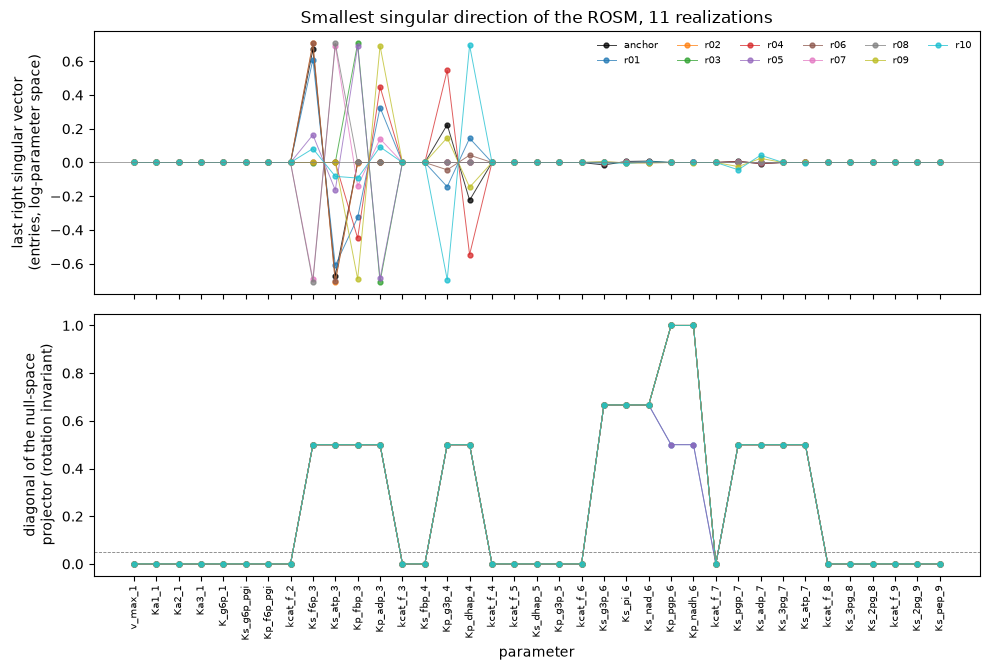

In [5]:
last_vector = read_optional(os.path.join(STRUCT, "last_right_singular_vector_before.csv"), index_col=0)
proj_diag = read_optional(os.path.join(STRUCT, "null_projector_diag_before.csv"), index_col=0)

if last_vector is not None and proj_diag is not None:
    fig, axes = plt.subplots(2, 1, figsize=(10, 6.8), sharex=True)
    ax_top = axes[0]
    ax_bot = axes[1]
    x_idx = np.arange(1, len(last_vector) + 1)

    for name in last_vector.columns:
        ax_top.plot(x_idx, last_vector[name].to_numpy(), marker="o", ms=3.5, lw=0.7, alpha=0.75, color=RUN_COLORS[name], label=name)
    ax_top.axhline(0.0, color="grey", lw=0.5)
    ax_top.set_ylabel("last right singular vector\n(entries, log-parameter space)")
    ax_top.set_title("Smallest singular direction of the ROSM, %d realizations" % len(last_vector.columns))
    ax_top.legend(ncol=6, fontsize=7, frameon=False, loc="upper right")

    for name in proj_diag.columns:
        ax_bot.plot(x_idx, proj_diag[name].to_numpy(), marker="o", ms=3.5, lw=0.7, alpha=0.75, color=RUN_COLORS[name], label=name)
    ax_bot.axhline(THRESHOLDS["structural_load_min"], color="grey", lw=0.6, ls="--")
    ax_bot.set_ylabel("diagonal of the null-space\nprojector (rotation invariant)")
    ax_bot.set_xticks(x_idx)
    ax_bot.set_xticklabels(list(last_vector.index), rotation=90, fontsize=7)
    ax_bot.set_xlabel("parameter")

    fig.tight_layout()
    plt.show()

## 3. Singular spectra before and after the structural fixing

The selection saves the spectrum of every structural check: `reduction/structural_spectra/it00_r0_anchored.csv` is the first check (all 37 parameters free), the following rounds of iteration 0 are after the structural fixes and refits (the table `structural_per_iteration.csv` lists them). The red dashed line is the structural-zero cut $10^{-10}$, the dotted one $10^{-6}$. After the fixing, the smallest singular ratio of the ROSM is many decades above the cut and the null dimension is 0.

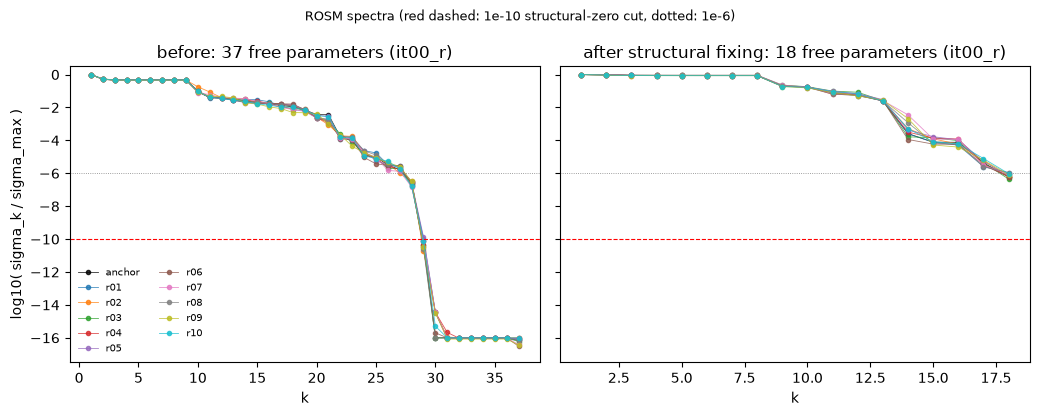

In [6]:
files = sorted(glob.glob(os.path.join(RED, "structural_spectra", "it00_r*_anchored.csv")))
if files:
    before = pd.read_csv(files[0], index_col=0)
    after = pd.read_csv(files[-1], index_col=0)
    names = list(before.columns)

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
    ax_left = axes[0]
    ax_right = axes[1]
    k_before = np.arange(1, len(before) + 1)
    k_after = np.arange(1, len(after) + 1)

    for name in names:
        ax_left.plot(k_before, np.log10(np.clip(before[name].to_numpy(), 1e-18, None)), marker="o", ms=3, lw=0.6, alpha=0.8, color=RUN_COLORS.get(name, "grey"), label=name)
    ax_left.axhline(np.log10(THRESHOLDS["structural_sv_tol"]), color="red", lw=0.8, ls="--")
    ax_left.axhline(-6, color="grey", lw=0.6, ls=":")
    ax_left.set_title("before: %d free parameters (%s)" % (len(before), os.path.basename(files[0])[:6]))
    ax_left.set_xlabel("k")
    ax_left.set_ylabel("log10( sigma_k / sigma_max )")
    ax_left.legend(ncol=2, fontsize=7, frameon=False, loc="lower left")

    for name in names:
        ax_right.plot(k_after, np.log10(np.clip(after[name].to_numpy(), 1e-18, None)), marker="o", ms=3, lw=0.6, alpha=0.8, color=RUN_COLORS.get(name, "grey"), label=name)
    ax_right.axhline(np.log10(THRESHOLDS["structural_sv_tol"]), color="red", lw=0.8, ls="--")
    ax_right.axhline(-6, color="grey", lw=0.6, ls=":")
    ax_right.set_title("after structural fixing: %d free parameters (%s)" % (len(after), os.path.basename(files[-1])[:6]))
    ax_right.set_xlabel("k")

    ax_left.set_ylim(-17.5, 0.5)
    fig.suptitle("ROSM spectra (red dashed: %.0e structural-zero cut, dotted: 1e-6)" % THRESHOLDS["structural_sv_tol"], fontsize=9)
    fig.tight_layout()
    plt.show()
else:
    print("no structural_spectra/it00_r*_anchored.csv in", RED)

### Reproducibility check of the live analysis

If the live cell has been run, its spectrum at the stage-0 anchor should coincide with `it00_r0_anchored.csv` of the selection (the selection restores the anchor with a tight warm start first, so the tail of the spectrum, which is numerical noise below $10^{-12}$, may differ).

In [7]:
spectra_before = read_optional(os.path.join(STRUCT, "spectra_before.csv"), index_col=0)
if spectra_before is not None and files:
    saved = pd.read_csv(files[0], index_col=0)
    top = slice(0, 25)
    diff = np.abs(np.log10(spectra_before.iloc[top].to_numpy()) - np.log10(saved.iloc[top].to_numpy()))
    print("largest difference in log10(sigma ratio) over the first 25 singular values: %.3f decades" % diff.max())

largest difference in log10(sigma ratio) over the first 25 singular values: 0.000 decades


## 4. Rate level and output level through the selection

Per structural check (`structural_per_iteration.csv`): the null dimension of the rate-level test, and of the output-level test without and with the active set of bounds. The output-level null space contains the rate-level one and is larger because free cofactors (Pi, ATP/ADP, NAD/NADH, glucose, pyruvate), free drains and the unmeasured states absorb rate changes. The protected parameters (the $k_\mathrm{cat}$ and the last parameter of a reaction) that remain in output-level groups are the nuisance set (`kept_free_by_rule`).

In [8]:
structural = read_optional(os.path.join(RED, "structural_per_iteration.csv"))
if structural is not None:
    structural["step"] = ["%s:%s" % (i, str(r).replace(".0", "")) for i, r in zip(structural["iter"], structural["round"])]  # iteration:round
    cols = ["step", "n_free", "sigma_ratio_anchor", "sigma_ratio_min_over_runs", "null_dim_consensus", "null_dim_perturbed_states",
            "out_null_dim", "out_null_dim_active_set", "n_exact", "n_mixed", "n_point_dependent", "n_output_level", "kept_free_by_rule"]
    display(structural[[c for c in cols if c in structural.columns]].set_index("step"))

,n_free,sigma_ratio_anchor,sigma_ratio_min_over_runs,null_dim_consensus,null_dim_perturbed_states,out_null_dim,out_null_dim_active_set,n_exact,n_mixed,n_point_dependent,n_output_level,kept_free_by_rule
step,,,,,,,,,,,,
0:0,37,6.891950e-17,3.123792e-17,8,8,22,20,7,0,0,22,NaN
0:1,29,1.139231e-11,5.039570e-12,1,0,14,14,0,0,1,14,NaN
0:2,28,1.114261e-07,7.667085e-08,0,0,14,14,0,0,0,14,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7
0:3,18,6.286217e-07,4.454375e-07,0,0,4,3,0,0,0,4,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7
1:0,18,6.286217e-07,4.970321e-07,0,0,4,3,0,0,0,4,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7
2:0,17,4.199970e-06,2.410824e-06,0,0,4,3,0,0,0,4,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7
3:0,16,4.199970e-06,2.253156e-06,0,0,4,3,0,0,0,4,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7
4:0,15,7.599116e-05,4.899858e-05,0,0,4,3,0,0,0,4,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7
5:0,14,2.564114e-04,1.033157e-04,0,0,4,3,0,0,0,4,K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7


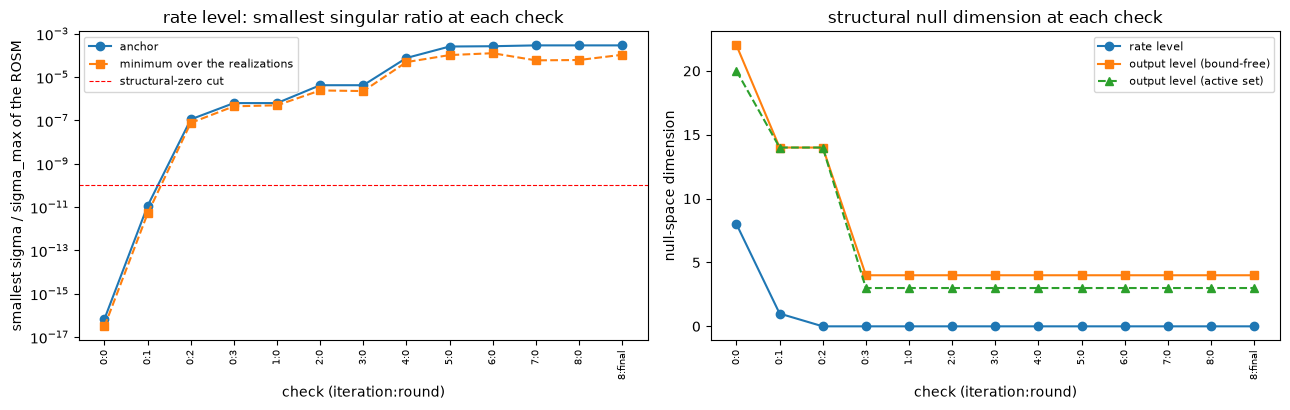

In [9]:
if structural is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    ax_sv, ax_null = axes
    x_step = np.arange(len(structural))

    ax_sv.semilogy(x_step, structural["sigma_ratio_anchor"], "o-", color="tab:blue", label="anchor")
    ax_sv.semilogy(x_step, structural["sigma_ratio_min_over_runs"], "s--", color="tab:orange", label="minimum over the realizations")
    ax_sv.axhline(THRESHOLDS["structural_sv_tol"], color="red", ls="--", lw=0.8, label="structural-zero cut")
    ax_sv.set_xticks(x_step)
    ax_sv.set_xticklabels(structural["step"], rotation=90, fontsize=7)
    ax_sv.set_xlabel("check (iteration:round)")
    ax_sv.set_ylabel("smallest sigma / sigma_max of the ROSM")
    ax_sv.legend(fontsize=8)
    ax_sv.set_title("rate level: smallest singular ratio at each check")

    ax_null.plot(x_step, structural["null_dim_consensus"], "o-", label="rate level")
    ax_null.plot(x_step, structural["out_null_dim"], "s-", label="output level (bound-free)")
    ax_null.plot(x_step, structural["out_null_dim_active_set"], "^--", label="output level (active set)")
    ax_null.set_xticks(x_step)
    ax_null.set_xticklabels(structural["step"], rotation=90, fontsize=7)
    ax_null.set_xlabel("check (iteration:round)")
    ax_null.set_ylabel("null-space dimension")
    ax_null.legend(fontsize=8)
    ax_null.set_title("structural null dimension at each check")

    fig.tight_layout()
    plt.show()

## 5. What the checks fixed

The structural rows of `fixing_log.csv`: `structural_exact` / `structural_pointdep` are rate-level groups (the partner is the member kept free), `structural_output` the output-level ones. The `trigger` column records the evidence (singular ratio below the cut in all $n$ runs, null dimension, null vector).

In [10]:
fix_log = read_optional(os.path.join(RED, "fixing_log.csv"))
if fix_log is not None:
    struct_fix = fix_log[fix_log["rule"].str.startswith("structural")]
    cols = ["param", "iter", "round", "rule", "partner", "group", "value_fixed", "influence_param", "output_class_at_fix", "trigger"]
    display(struct_fix[[c for c in cols if c in struct_fix.columns]])
    print(struct_fix.groupby("rule").size().rename("n fixed").to_frame().T.to_string())

,param,iter,round,rule,partner,group,value_fixed,influence_param,output_class_at_fix,trigger
0,Ks_atp_3,0,0.0,structural_exact,Ks_f6p_3,Ks_f6p_3;Ks_atp_3,0.001972,6.865369e-01,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*Ks_f6p_3 -1*Ks_atp_3)"
1,Kp_adp_3,0,0.0,structural_exact,Kp_fbp_3,Kp_fbp_3;Kp_adp_3,0.002101,6.863315e-01,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*Kp_fbp_3 -1*Kp_adp_3)"
2,Kp_g3p_4,0,0.0,structural_exact,Kp_dhap_4,Kp_g3p_4;Kp_dhap_4,5.538993,1.610152e-06,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*Kp_g3p_4 -1*Kp_dhap_4)"
3,Ks_g3p_6,0,0.0,structural_exact,Ks_pi_6,Ks_g3p_6;Ks_pi_6;Ks_nad_6,0.005013,5.977163e-04,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 2, +1*Ks_g3p_6 -1*Ks_nad_6 | +1*Ks_pi_6 -1*Ks_na..."
4,Ks_nad_6,0,0.0,structural_exact,Ks_pi_6,Ks_g3p_6;Ks_pi_6;Ks_nad_6,0.005013,5.977151e-04,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 2, +1*Ks_g3p_6 -1*Ks_nad_6 | +1*Ks_pi_6 -1*Ks_na..."
5,Kp_nadh_6,0,0.0,structural_exact,Kp_pgp_6,Kp_pgp_6;Kp_nadh_6,2.996095,5.637182e-07,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*Kp_pgp_6 -1*Kp_nadh_6)"
6,Ks_pgp_7,0,0.0,structural_exact,Ks_adp_7,Ks_pgp_7;Ks_adp_7,0.001241,2.779808e-03,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*Ks_pgp_7 -1*Ks_adp_7)"
7,Ks_3pg_7,0,0.0,structural_exact,Ks_atp_7,Ks_3pg_7;Ks_atp_7,3.654498,1.603780e-05,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*Ks_3pg_7 -1*Ks_atp_7)"
8,Kp_pgp_6,0,1.0,structural_pointdep,NaN,Kp_pgp_6,8.180164,2.875369e-06,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*Kp_pgp_6)"
9,v_max_1,0,2.0,structural_output,NaN,v_max_1,80.209416,1.989346e-03,non_identifiable,"sigma_ratio<1e-10 in all 11 runs (dim 1, +1*v_max_1)"


rule     structural_exact  structural_output  structural_pointdep
n fixed                 8                 10                    1


### Output-level classes of the final structure

Classes of the free parameters at the final anchor (`final/output_level_classes.csv`, written by `final_fit.ipynb`): `identifiable`, `bound_identified` (identifiable only because a free variable sits on a bound) and `non_identifiable` (absorbed by the free cofactors, drains or unmeasured states; for $k_\mathrm{cat}$ and last-in-group parameters these are the nuisance parameters).

In [11]:
classes = read_optional(os.path.join(OUT, "final", "output_level_classes.csv"))
if classes is not None:
    display(classes.set_index("param").T)

param,K_g6p_1,Ks_g6p_pgi,kcat_f_2,kcat_f_3,Ks_fbp_4,kcat_f_4,kcat_f_5,kcat_f_6,kcat_f_7,kcat_f_8,kcat_f_9
output_class,non_identifiable,identifiable,identifiable,bound_identified,identifiable,identifiable,identifiable,non_identifiable,non_identifiable,identifiable,identifiable
